# 02 — Data preprocessing and engine-separated LSTM sequences

Run the project-paths cell first. Paths work from the project root or the notebooks folder.
Existing outputs are retained from the last run; historical path messages may show the former layout.
See [the project README](../README.md) for run order and current limitations.


In [ ]:
from pathlib import Path

# Locate the project whether the kernel starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'requirements.txt').is_file()
     and (folder / 'notebooks').is_dir()
     and (folder / 'README.md').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Start this notebook from inside the Predictive maintenance for IoT project.')
RAW_DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'cmapss'
PROCESSED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
TABLES_DIR = PROJECT_ROOT / 'reports' / 'tables'
print(f'Project root: {PROJECT_ROOT}')


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

np.random.seed(34)

In [3]:
index_name = ['unit_number', 'time_in_cycles']
setting_name = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['s_{}'.format(i+1) for i in range(0,21)]
col_names = index_name + setting_name + sensor_names

In [4]:
print(col_names)

['unit_number', 'time_in_cycles', 'setting_1', 'setting_2', 'setting_3', 's_1', 's_2', 's_3', 's_4', 's_5', 's_6', 's_7', 's_8', 's_9', 's_10', 's_11', 's_12', 's_13', 's_14', 's_15', 's_16', 's_17', 's_18', 's_19', 's_20', 's_21']


In [5]:
data = pd.read_csv(RAW_DATA_DIR / 'train_FD001.txt', sep=r"\s+", header=None, names=col_names)
data.head(5)


,unit_number,time_in_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
testdata = pd.read_csv(RAW_DATA_DIR / 'test_FD001.txt', sep=r"\s+", header=None, names=col_names)
testdata.head(5)

,unit_number,time_in_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [7]:
train= data.copy()
test= testdata.copy()

In [8]:
y_RUL = pd.read_csv(RAW_DATA_DIR / 'RUL_FD001.txt',sep=r'\s+',header=None,index_col=False,names=['RUL'])
y_RUL.head(5)

,RUL
0,112
1,98
2,69
3,82
4,91


In [9]:
print('Shape of the train dataset : ',train.shape)
print('Shape of the validation dataset : ',y_RUL.shape)
print('Shape of the test dataset : ',test.shape)
print('Percentage of the validation dataset : ',len(test)/(len(test)+len(train)))

Shape of the train dataset :  (20631, 26)
Shape of the validation dataset :  (100, 1)
Shape of the test dataset :  (13096, 26)
Percentage of the validation dataset :  0.3882942449669404


# Data Cleaning

In [10]:
unique_counts = train.nunique()

In [11]:
constant_cols = unique_counts[unique_counts == 1].index.tolist()
print(f"Constant Columns found: {constant_cols}")

Constant Columns found: ['setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19']


In [12]:
#Drop constant columns
df_clean=train.drop(columns=constant_cols)

In [13]:
df_clean.head(5)

,unit_number,time_in_cycles,setting_1,setting_2,s_2,s_3,s_4,s_6,s_7,s_8,s_9,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044


In [14]:
df_clean.isnull().sum()

unit_number       0
time_in_cycles    0
setting_1         0
setting_2         0
s_2               0
s_3               0
s_4               0
s_6               0
s_7               0
s_8               0
s_9               0
s_11              0
s_12              0
s_13              0
s_14              0
s_15              0
s_17              0
s_20              0
s_21              0
dtype: int64

In [15]:
df_clean.loc[:,['unit_number','time_in_cycles']].describe()

,unit_number,time_in_cycles
count,20631.000000,20631.000000
mean,51.506568,108.807862
std,29.227633,68.880990
min,1.000000,1.000000
25%,26.000000,52.000000
50%,52.000000,104.000000
75%,77.000000,156.000000
max,100.000000,362.000000


we notice that there is no null values in our dataset and there are no missing value is detected

So now we are goin to remove s_6 becous it's variance is so  small it is almost dead , that is gonna make no defrence for remaining usfull time 

and sense we have that s_9 (Physical Core Speed)  and s_14 (Corrected Core Speed) are high correlated sonsors we are goin to remove the s_9

In [16]:
df_clean = df_clean.drop(['setting_1', 'setting_2', 's_6', 's_9'], axis=1)

In [17]:
df_clean.shape

(20631, 15)

Let us see the maximum time cycle of each unit

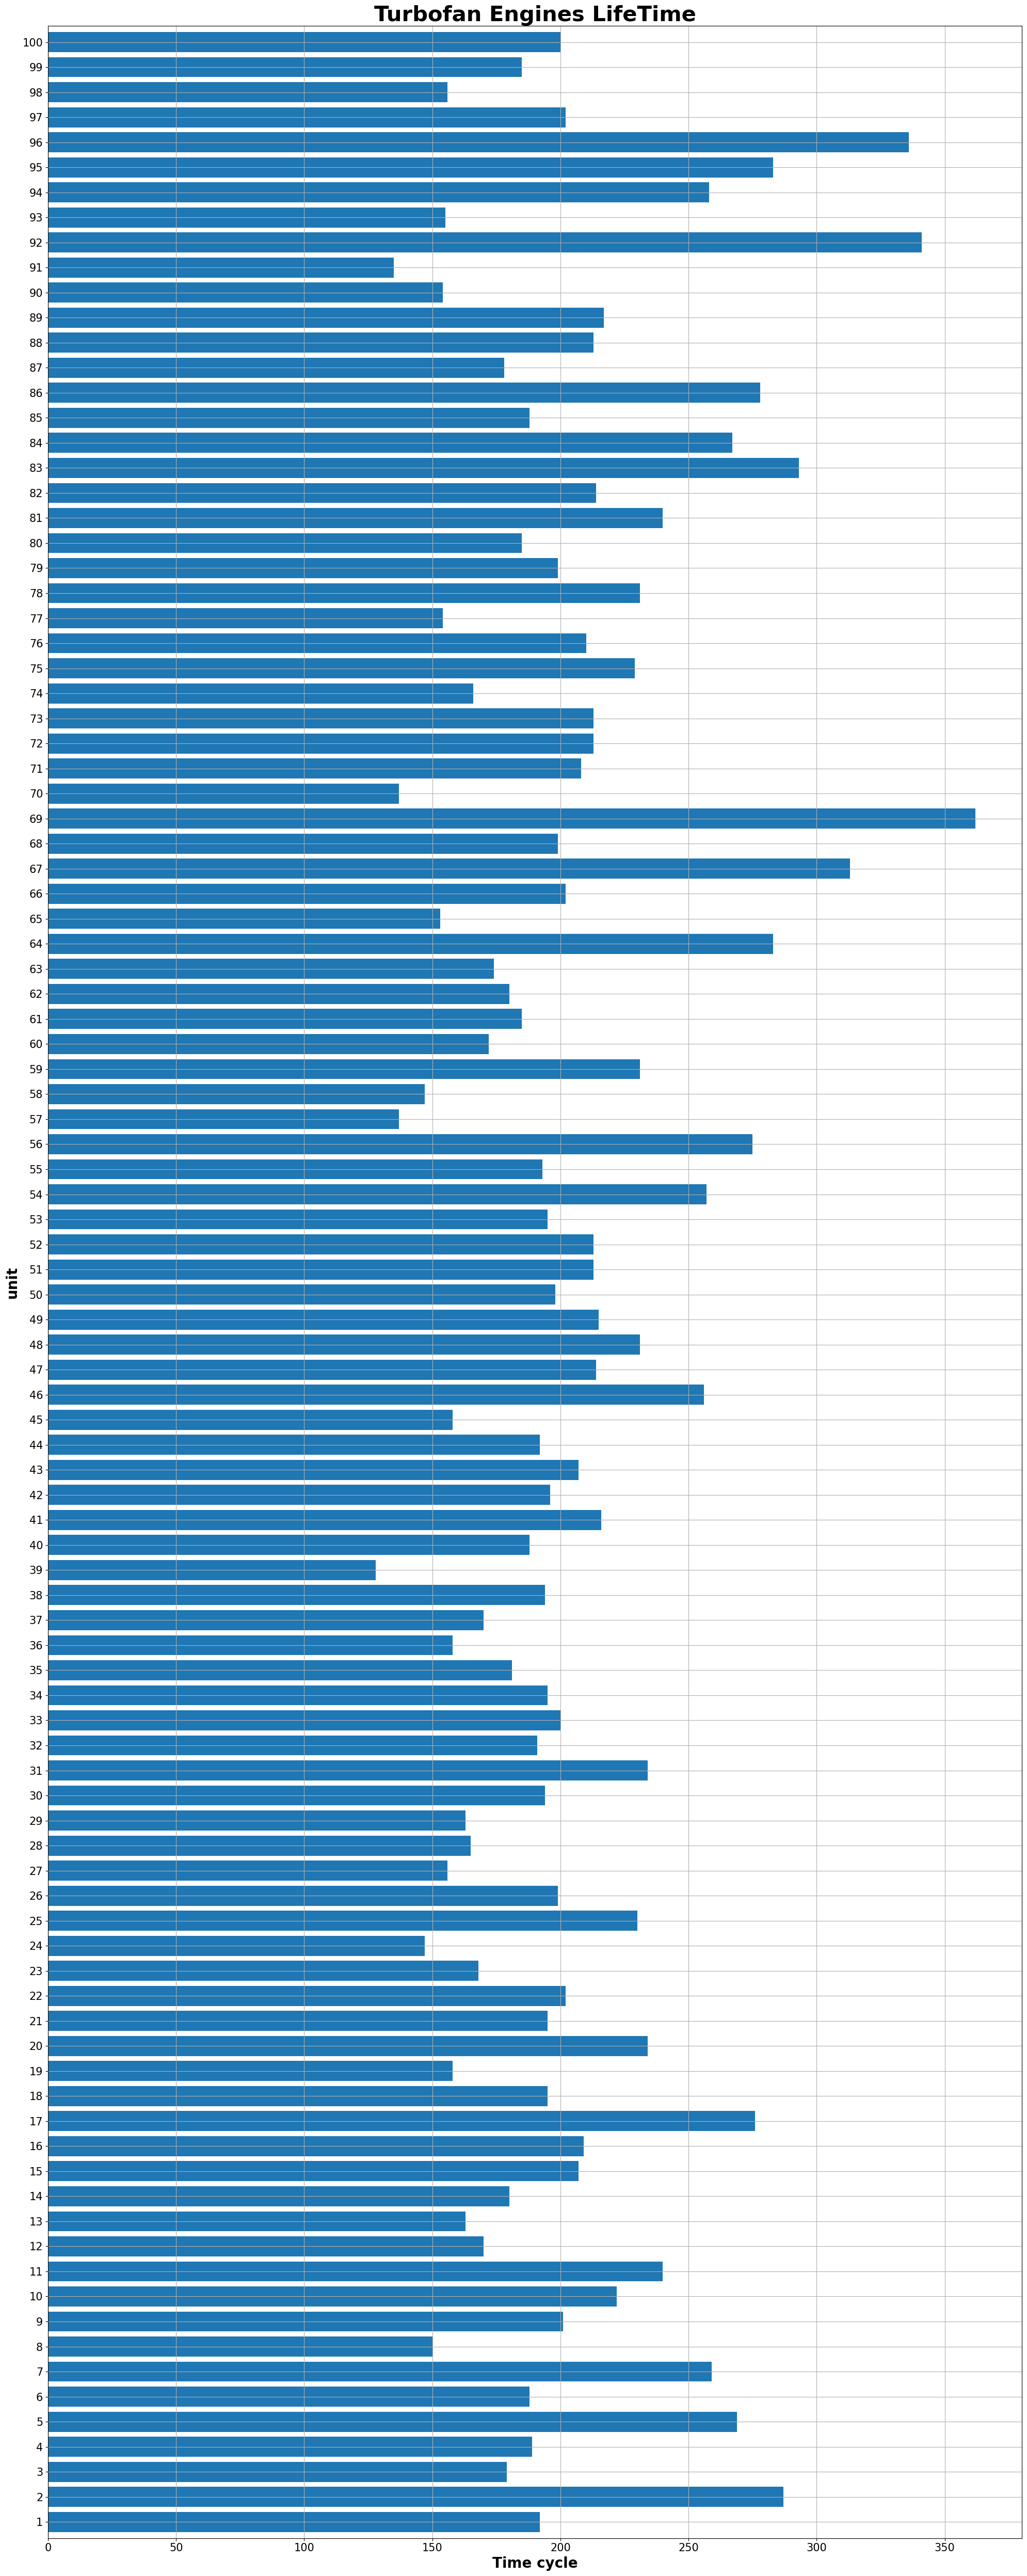

In [18]:
max_time_cycles=df_clean[index_name].groupby('unit_number').max()
plt.figure(figsize=(20,50))
ax=max_time_cycles['time_in_cycles'].plot(kind='barh',width=0.8, stacked=True,align='center')
plt.title('Turbofan Engines LifeTime',fontweight='bold',size=30)
plt.xlabel('Time cycle',fontweight='bold',size=20)
plt.xticks(size=15)
plt.ylabel('unit',fontweight='bold',size=20)
plt.yticks(size=15)
plt.grid(True)
plt.tight_layout()
plt.show()

Text(0.5, 9.444444444444459, 'max time cycle')

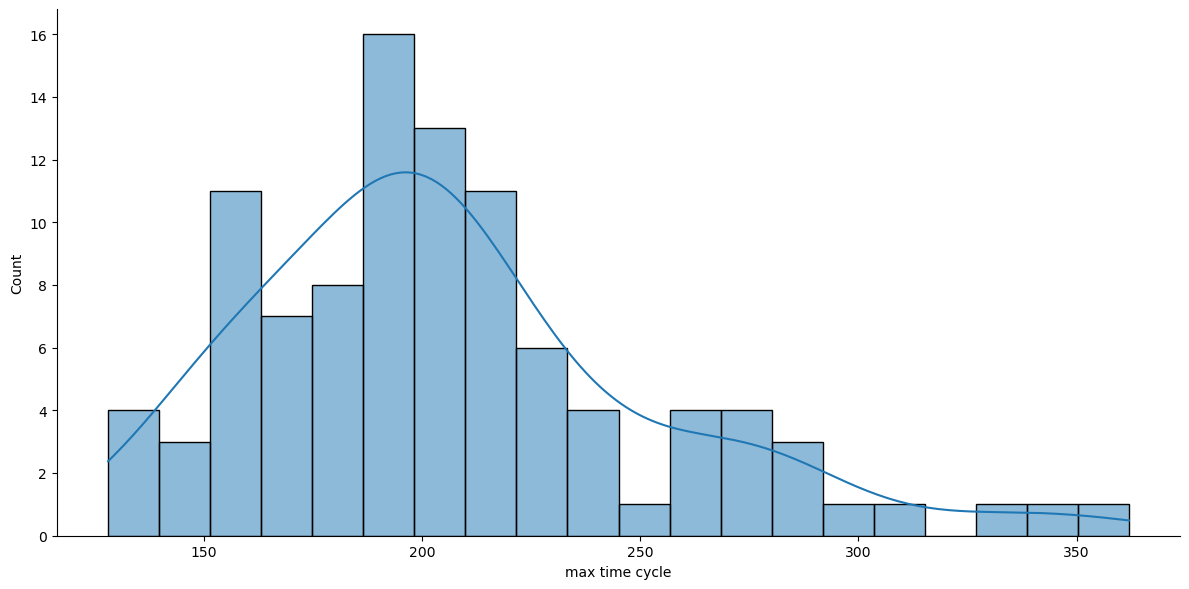

In [19]:
#Distribution of maximum time cycles
sns.displot(max_time_cycles['time_in_cycles'],kde=True,bins=20,height=6,aspect=2)
plt.xlabel('max time cycle')

We notice that in most of the time, the maximum time cycles that an engine can achieve is between 190 and 210 before HPC failure.

we are done with data cleaning now we are goin to move for:
# Add the RUL Target (The countdown).

In [20]:
def add_RUL_target(df):
    df_clean_grouped = df.groupby(by='unit_number')
    max_time_cycles = df_clean_grouped['time_in_cycles'].max()
    merged = df.merge(max_time_cycles.to_frame(name='max_time_cycles'), left_on='unit_number', right_index=True)
    merged['RUL'] = merged['max_time_cycles'] - merged['time_in_cycles']
    merged = merged.drop(columns=['max_time_cycles'])
    return merged

In [21]:
df_clean  = add_RUL_target(df_clean)

In [22]:
df_clean.shape

(20631, 16)

In [23]:
df_clean.head(5)

,unit_number,time_in_cycles,s_2,s_3,s_4,s_7,s_8,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21,RUL
0,1,1,641.82,1589.70,1400.60,554.36,2388.06,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,642.15,1591.82,1403.14,553.75,2388.04,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,642.35,1587.99,1404.20,554.26,2388.08,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,642.35,1582.79,1401.87,554.45,2388.11,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,642.37,1582.85,1406.22,554.00,2388.06,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187


In [24]:
df_clean[['unit_number', 'time_in_cycles', 'RUL']]

,unit_number,time_in_cycles,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
...,...,...,...
20626,100,196,4
20627,100,197,3
20628,100,198,2
20629,100,199,1


In [25]:
#Rul analysis
maxrul_u = df_clean.groupby('unit_number').max().reset_index()
maxrul_u.head()

,unit_number,time_in_cycles,s_2,s_3,s_4,s_7,s_8,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21,RUL
0,1,192,644.21,1605.44,1432.52,554.96,2388.32,48.33,522.86,2388.35,8140.58,8.5227,398,39.18,23.4999,191
1,2,287,643.94,1610.10,1431.17,555.45,2388.24,48.27,523.26,2388.26,8175.57,8.5377,398,39.24,23.6005,286
2,3,179,643.93,1606.50,1438.51,555.28,2388.19,48.38,523.18,2388.20,8255.34,8.5363,399,39.23,23.5181,178
3,4,189,644.53,1612.11,1434.12,554.75,2388.18,48.21,522.48,2388.17,8259.42,8.5462,399,39.21,23.5074,188
4,5,269,644.02,1609.41,1434.59,555.57,2388.21,48.27,523.04,2388.23,8215.19,8.5410,398,39.29,23.5503,268


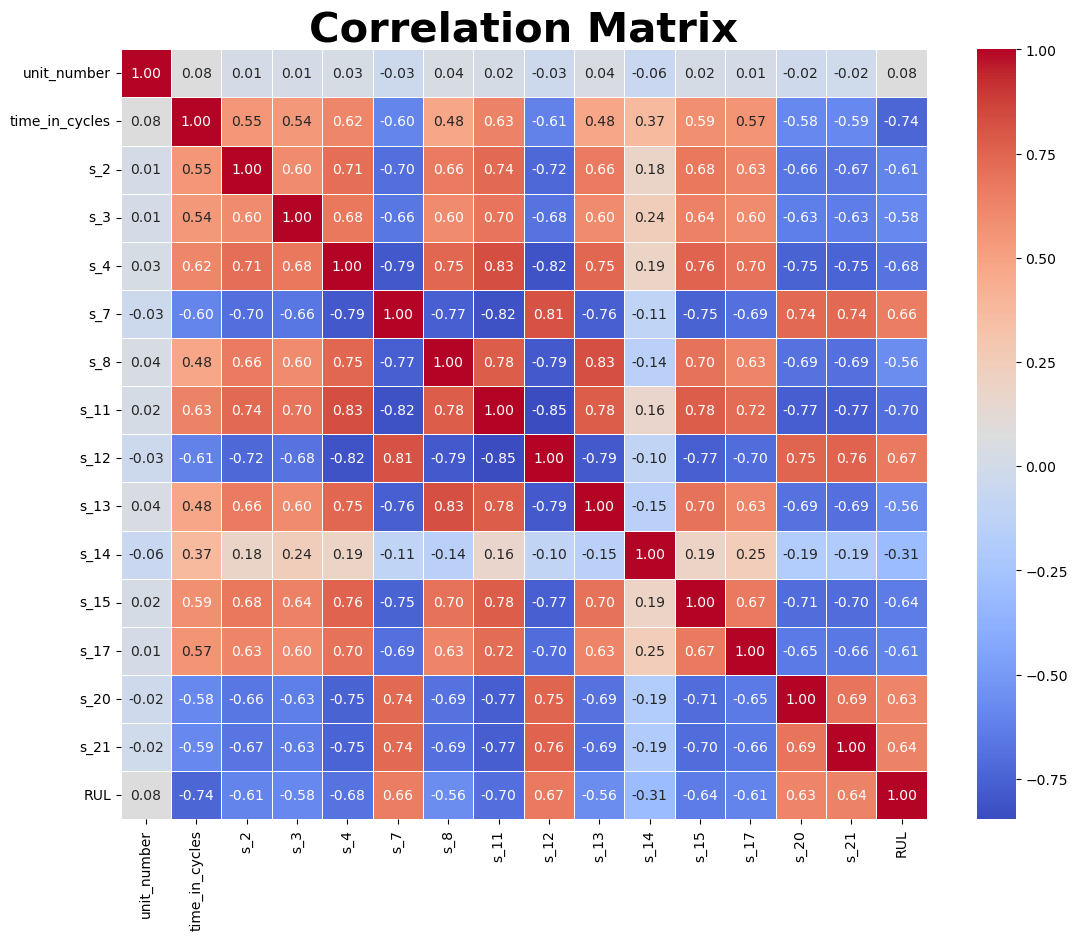

In [26]:
#correlation matrex
corr_matrix = df_clean.corr()
plt.figure(figsize=(13,10))
sns.heatmap(corr_matrix, 
            annot=True,      # Show the numbers on the squares
            cmap='coolwarm', # Blue = Negative corr, Red = Positive corr
            fmt=".2f",       # Format to 2 decimal places
            linewidths=0.5)

plt.title('Correlation Matrix', fontweight='bold', size=30)
plt.show()


In [27]:
dict_map = {
    "s_2": "(LPC outlet temperature) (◦R)",
    "s_3": "(HPC outlet temperature) (◦R)",
    "s_4": "(LPT outlet temperature) (◦R)",
    "s_7": "(HPC outlet pressure) (psia)",
    "s_8": "(Physical fan speed) (rpm)",
    "s_9": "(Physical core speed) (rpm)",
    "s_11": "(HPC outlet Static pressure) (psia)",
    "s_12": "(Ratio of fuel flow to Ps30) (pps/psia)",
    "s_13": "(Corrected fan speed) (rpm)",
    "s_15": "(Bypass Ratio)",
    "s_17": "(Bleed Enthalpy)",
    "s_20": "(High-pressure turbines Cool air flow)",
    "s_21": "(Low-pressure turbines Cool air flow)"
}

Sensor_dictionary = {}

for col in df_clean.columns:
    if col in dict_map:
        Sensor_dictionary[col] = dict_map[col]

Sensor_dictionary


{'s_2': '(LPC outlet temperature) (◦R)',
 's_3': '(HPC outlet temperature) (◦R)',
 's_4': '(LPT outlet temperature) (◦R)',
 's_7': '(HPC outlet pressure) (psia)',
 's_8': '(Physical fan speed) (rpm)',
 's_11': '(HPC outlet Static pressure) (psia)',
 's_12': '(Ratio of fuel flow to Ps30) (pps/psia)',
 's_13': '(Corrected fan speed) (rpm)',
 's_15': '(Bypass Ratio)',
 's_17': '(Bleed Enthalpy)',
 's_20': '(High-pressure turbines Cool air flow)',
 's_21': '(Low-pressure turbines Cool air flow)'}

A **low pressure compressor (LPC)** and **high pressure compressor (HPC)** supply compressed high temperature, high pressure gases to the combustor. **Low pressure turbine (LPT)** can decelerate and pressurize air to improve the chemical energy conversion efficiency of aviation kerosene. **High pressure turbines (HPT)** generate mechanical energy by using high temperature and high pressure gas strike turbine blades. **Low-pressure rotor (N1)**, **high-pressure rotor (N2)**, and nozzle guarantee the combustion efficiency of the engine.

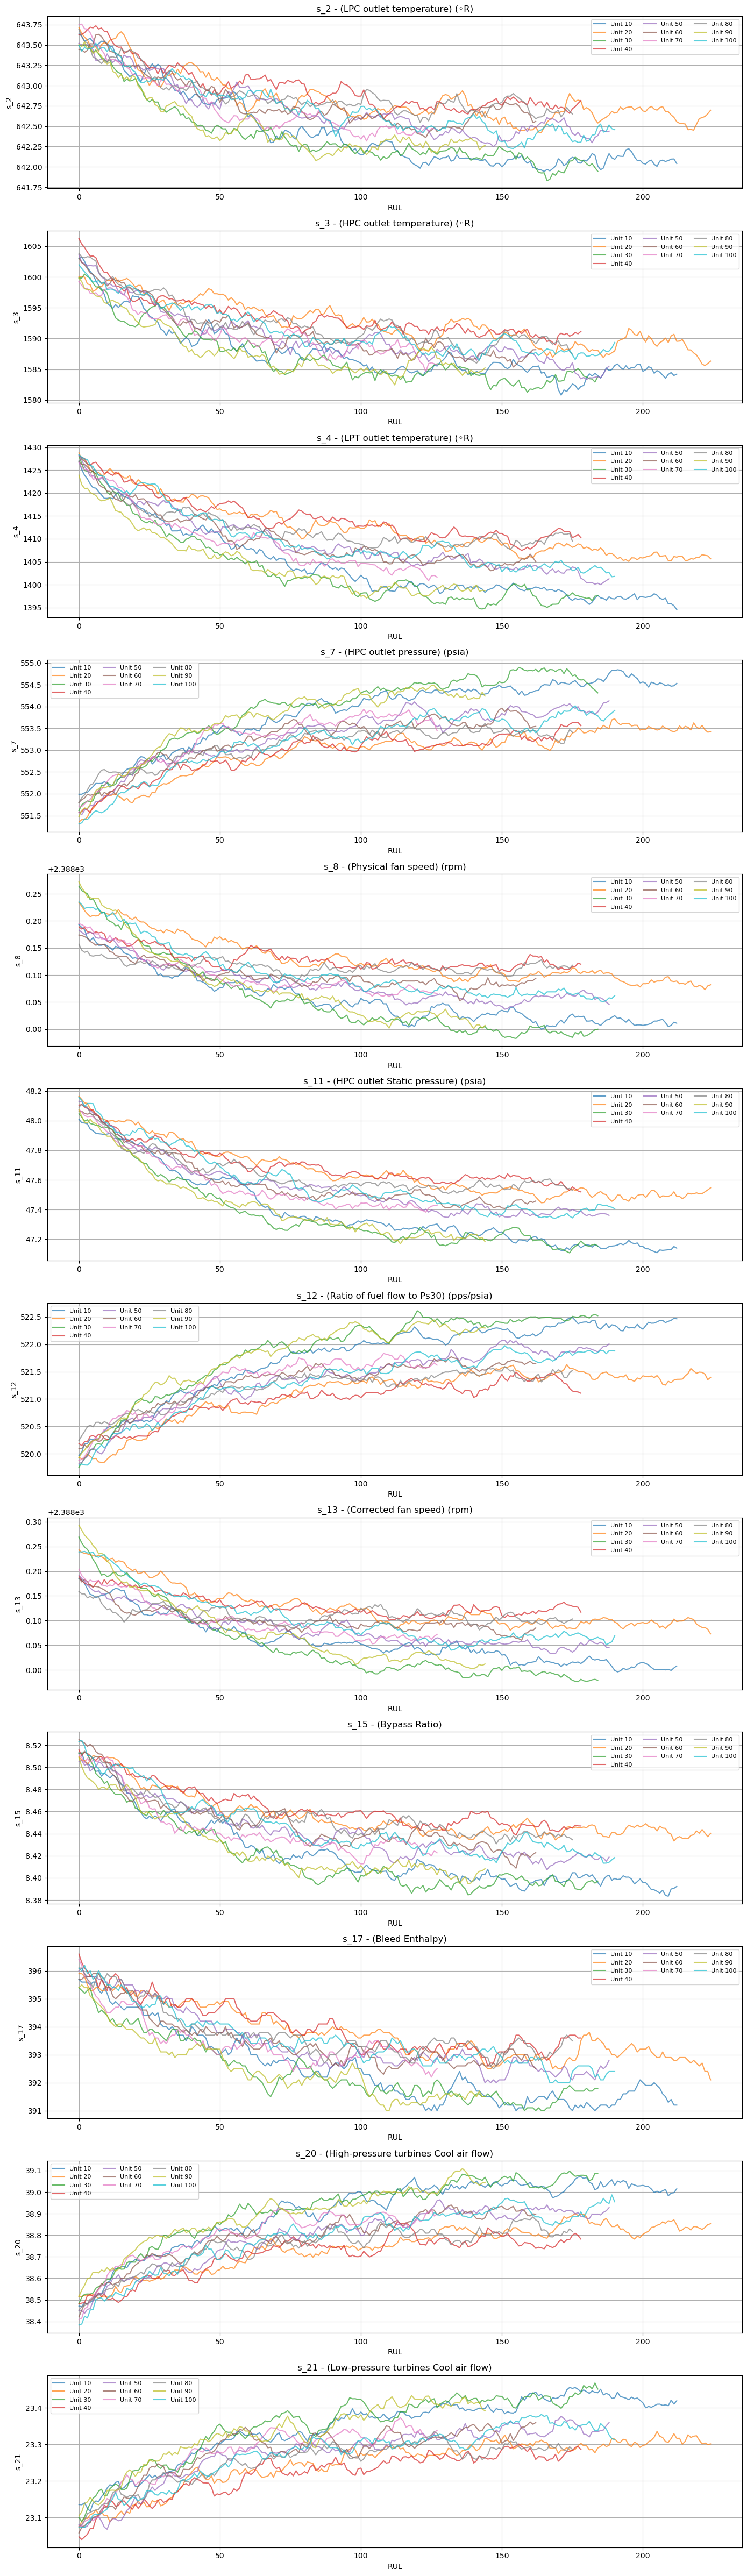

In [28]:
sensor_cols = list(Sensor_dictionary.keys())

# Select only 20 units for visualization
units_to_plot = [u for u in df_clean['unit_number'].unique() if u % 10 == 0][:20]

plt.figure(figsize=(14, 4 * len(sensor_cols)))

for idx, sensor in enumerate(sensor_cols, 1):

    plt.subplot(len(sensor_cols), 1, idx)

    for u in units_to_plot:
        df_u = df_clean[df_clean['unit_number'] == u].copy()
        df_u[sensor + "_rm"] = df_u[sensor].rolling(10).mean()  # smoothing

        plt.plot(df_u["RUL"], df_u[sensor + "_rm"], label=f"Unit {u}", alpha=0.7)

    plt.xlabel("RUL")
    plt.ylabel(sensor)
    plt.title(f"{sensor} - {Sensor_dictionary[sensor]}")
    plt.grid(True)
    plt.legend(fontsize=8, ncol=3)

plt.tight_layout()
plt.show()

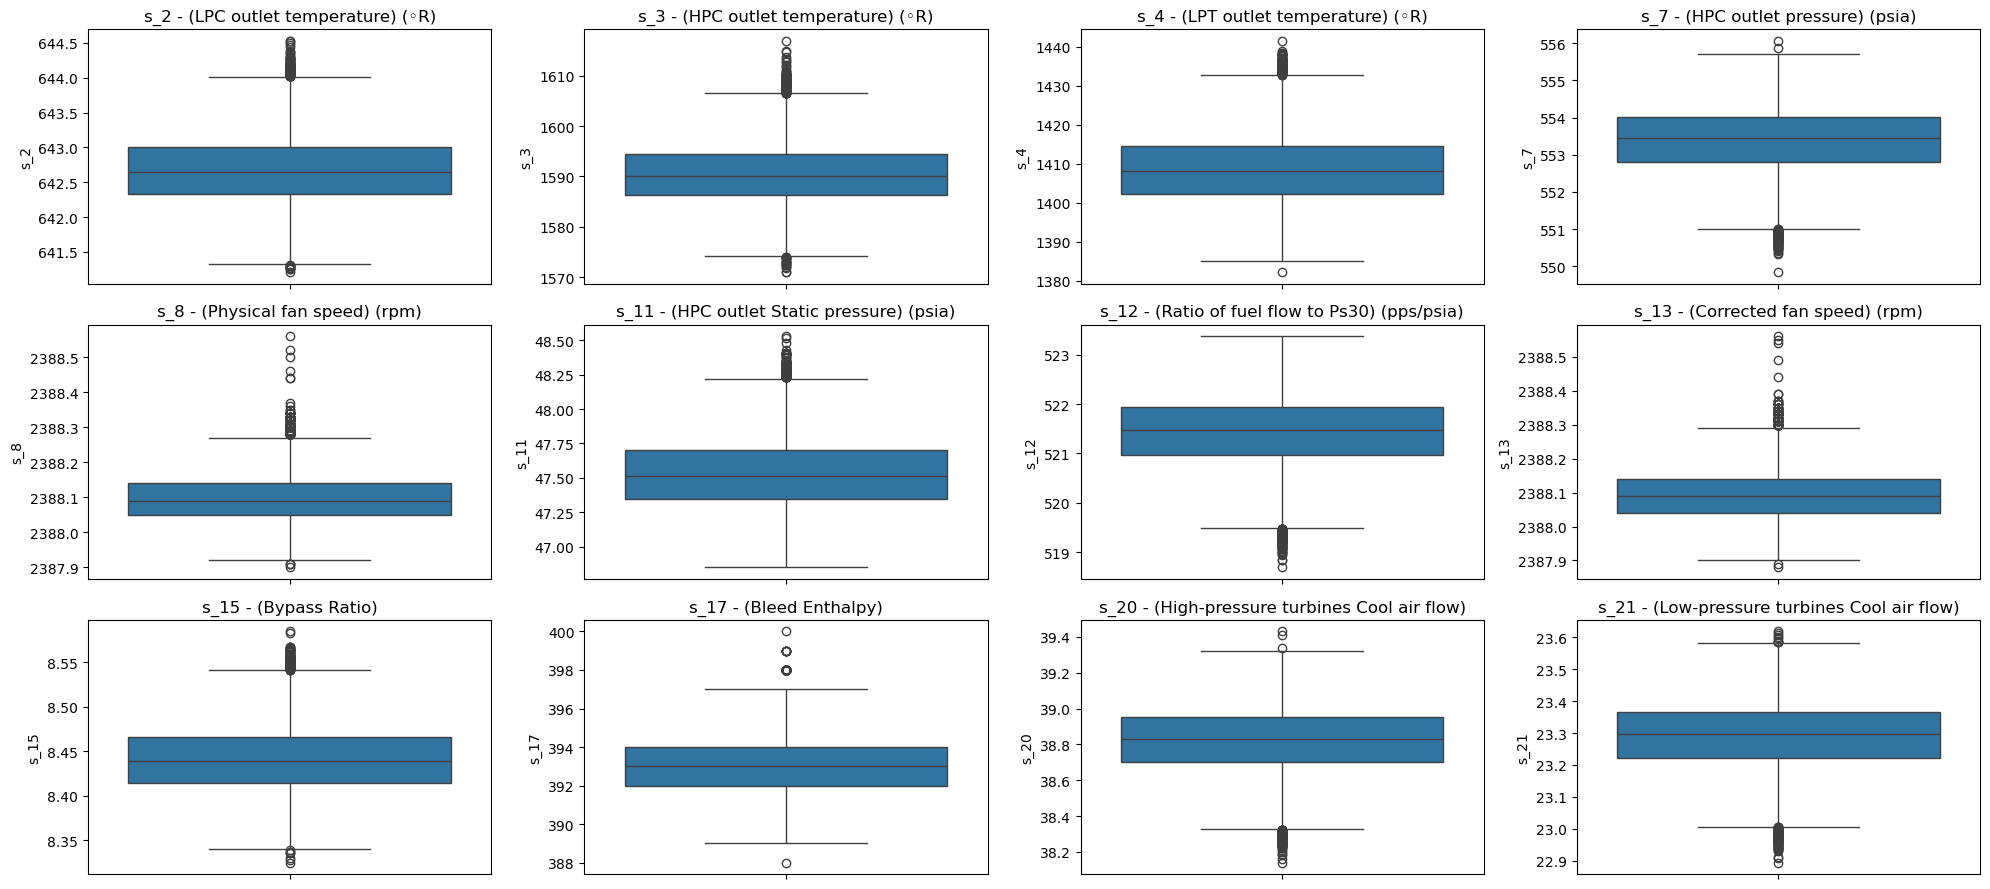

In [29]:
import math

# Define subplot grid
n_cols = 4
n_rows = math.ceil(len(sensor_cols) / n_cols)

plt.figure(figsize=(20, n_rows * 3))
for i, sensor in enumerate(sensor_cols):
    plt.subplot(n_rows, n_cols, i+1)
    sns.boxplot(y=df_clean[sensor])
    plt.title(f"{sensor} - {Sensor_dictionary[sensor]}")
    plt.tight_layout()

plt.show()

We observe that the other sensors aren't well distributed and there are many outliers, then we should scale our data.

The last point is more supported by the fact that the statistic properties of sensors data show that they don't have the same scale and they don't follow a normal distribution ==> this can be solved by performing a Minmax scaler on our data.

**MinMax scaler function :** Transform features by scaling each feature to a given range.

This estimator scales and translates each feature individually such that it is in the given range on the training set:
$$
x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$




In [30]:
from sklearn.preprocessing import MinMaxScaler

# 1. Define which columns to scale (Only the sensors!)
# We do NOT scale 'unit_nr', 'time_cycles', or 'RUL'
features_to_scale = [col for col in df_clean.columns if 's_' in col]

# 2. Initialize the Scaler
scaler = MinMaxScaler(feature_range=(0, 1))

# 3. Fit and Transform
# Note: We are overwriting the original columns with the scaled versions
df_clean[features_to_scale] = scaler.fit_transform(df_clean[features_to_scale])

print("Data Normalized.")
print(df_clean.head())

Data Normalized.
   unit_number  time_in_cycles       s_2       s_3       s_4       s_7  \
0            1               1  0.183735  0.406802  0.309757  0.726248   
1            1               2  0.283133  0.453019  0.352633  0.628019   
2            1               3  0.343373  0.369523  0.370527  0.710145   
3            1               4  0.343373  0.256159  0.331195  0.740741   
4            1               5  0.349398  0.257467  0.404625  0.668277   

        s_8      s_11      s_12      s_13      s_14      s_15      s_17  \
0  0.242424  0.369048  0.633262  0.205882  0.199608  0.363986  0.333333   
1  0.212121  0.380952  0.765458  0.279412  0.162813  0.411312  0.333333   
2  0.272727  0.250000  0.795309  0.220588  0.171793  0.357445  0.166667   
3  0.318182  0.166667  0.889126  0.294118  0.174889  0.166603  0.333333   
4  0.242424  0.255952  0.746269  0.235294  0.174734  0.402078  0.416667   

       s_20      s_21  RUL  
0  0.713178  0.724662  191  
1  0.666667  0.731014  190  


array([[<Axes: title={'center': 's_2'}>, <Axes: title={'center': 's_3'}>,
        <Axes: title={'center': 's_4'}>, <Axes: title={'center': 's_7'}>],
       [<Axes: title={'center': 's_8'}>,
        <Axes: title={'center': 's_11'}>,
        <Axes: title={'center': 's_12'}>,
        <Axes: title={'center': 's_13'}>],
       [<Axes: title={'center': 's_14'}>,
        <Axes: title={'center': 's_15'}>,
        <Axes: title={'center': 's_17'}>,
        <Axes: title={'center': 's_20'}>],
       [<Axes: title={'center': 's_21'}>, <Axes: >, <Axes: >, <Axes: >]],
      dtype=object)

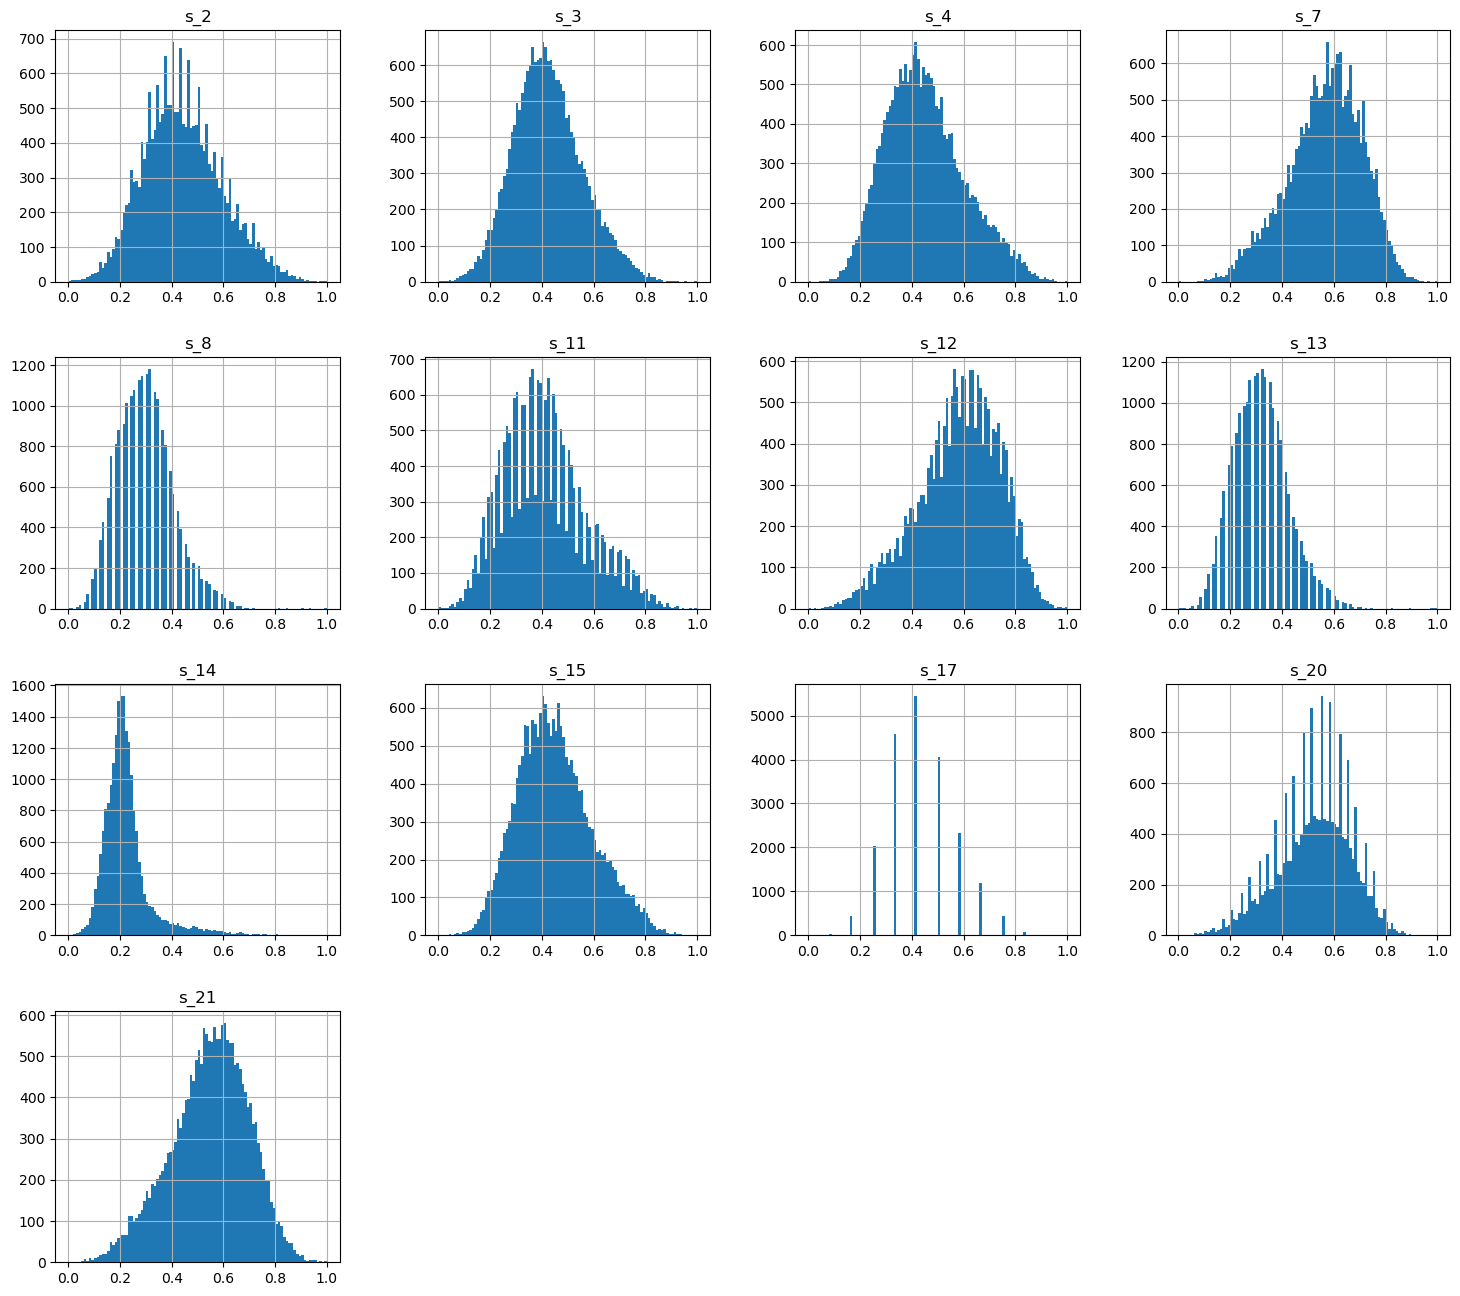

In [31]:
sensor_names=['s_{}'.format(i) for i in range(1,22) if i not in [1,5,6,9,10,16,18,19]]
pd.DataFrame(df_clean,columns=['s_{}'.format(i) for i in range(1,22)])[sensor_names].hist(bins=100, figsize=(18,16))

# PREPARE DATA FOR PCA

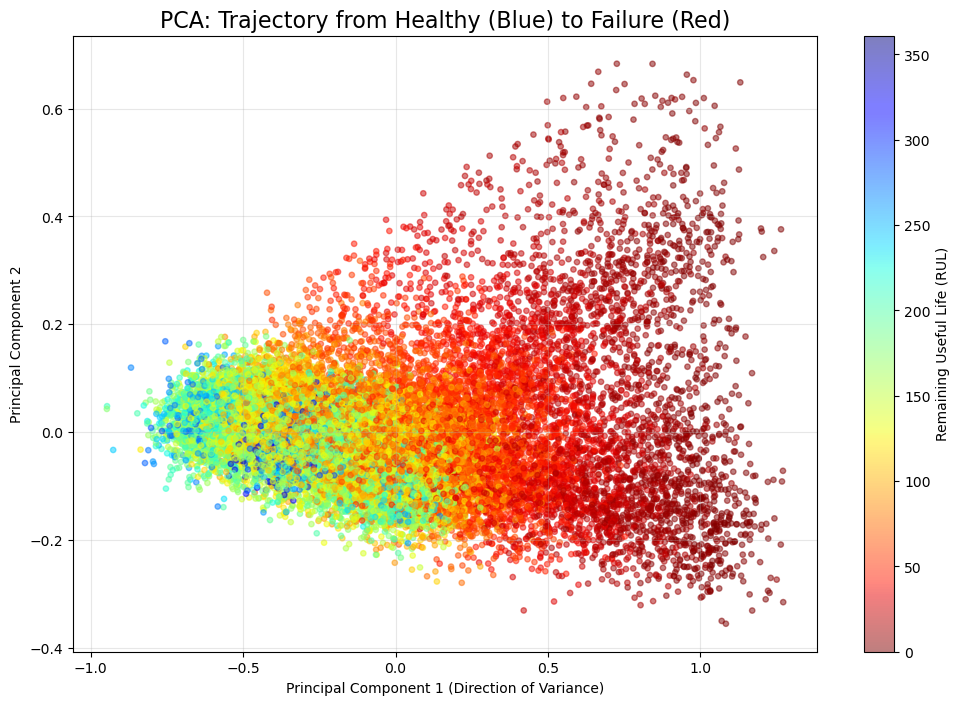

Variance explained by PC1 & PC2: 77.44%


In [32]:
from sklearn.decomposition import PCA


features_for_pca = [col for col in df_clean.columns if 's_' in col]
# The data is already normalized so we use it directly.
X_pca_input = df_clean[features_for_pca]

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_pca_input)

# CREATE DATAFRAME FOR PLOTTING
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])

# Add the labels back from the original df_clean for coloring/grouping
pca_df['RUL'] = df_clean['RUL']         
pca_df['Unit'] = df_clean['unit_number']
plt.figure(figsize=(12, 8))

# Scatter plot
sc = plt.scatter(pca_df['PC1'], pca_df['PC2'], 
                 c=pca_df['RUL'], 
                 cmap='jet_r', # Red = Low RUL (Danger), Blue = High RUL (Healthy)
                 s=15,         # Slightly larger dots for visibility
                 alpha=0.5)    # Transparency to see density

plt.colorbar(sc, label='Remaining Useful Life (RUL)')
plt.xlabel('Principal Component 1 (Direction of Variance)')
plt.ylabel('Principal Component 2')
plt.title('PCA: Trajectory from Healthy (Blue) to Failure (Red)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.show()


# This tells you how much information is preserved in just 2 dimensions
print(f"Variance explained by PC1 & PC2: {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

getting 77.44% variance explained with just the first two principal components is very high.
that means: 
The sensors are moving together in a very strong, clear pattern. The "noise" is low compared to the "signal."

# Sliding Window (The 3D Transformation)

Current shape: a table of sensor readings, one row per engine cycle.

LSTM shape: (samples, 30 time steps, 13 sensor features).
Windows overlap with stride 1, within each engine only. Cycles 1-30 predict
RUL at cycle 30; cycles 2-31 predict RUL at cycle 31. Include the final window.

The preparation below rebuilds sensor values from raw `data`, splits engine IDs
80/20 with seed 42 before creating windows, and fits a separate scaler using only
training engines. The earlier all-engine scaling is for exploration only.
Corrected arrays and their scaler are saved to `data/processed/lstm_fd001/`.
Run this section before restarting and running the DL training notebook.
Previous trained models need retraining; their metrics and SHAP plots describe the old pipeline.

In [33]:
def gen_sequence(df, seq_length, seq_cols):
    """Yield stride-1 windows for one engine, including its final cycle."""
    if seq_length < 1:
        raise ValueError("seq_length must be positive")
    data_matrix = df.sort_values('time_in_cycles')[seq_cols].to_numpy()
    for stop in range(seq_length, len(data_matrix) + 1):
        yield data_matrix[stop - seq_length:stop]

In [34]:
def gen_labels(df, seq_length, label_col):
    """Use the target at the final observed cycle of each window."""
    if seq_length < 1:
        raise ValueError("seq_length must be positive")
    values = df.sort_values('time_in_cycles')[label_col].to_numpy()
    return values[seq_length - 1:]

In [35]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler

sequence_length = 30
sensor_cols = ['s_2', 's_3', 's_4', 's_7', 's_8', 's_11', 's_12',
               's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
sequence_cols = sensor_cols

# Rebuild from RAW readings, not the previously scaled EDA dataframe.
lstm_df = add_RUL_target(data[['unit_number', 'time_in_cycles'] + sensor_cols].copy())
lstm_df = lstm_df.sort_values(['unit_number', 'time_in_cycles']).reset_index(drop=True)
assert not lstm_df.duplicated(['unit_number', 'time_in_cycles']).any()

splitter = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_rows, val_rows = next(splitter.split(lstm_df, groups=lstm_df['unit_number']))
train_units = np.sort(lstm_df.iloc[train_rows]['unit_number'].unique())
val_units = np.sort(lstm_df.iloc[val_rows]['unit_number'].unique())
assert set(train_units).isdisjoint(val_units)

lstm_scaler = MinMaxScaler()
lstm_scaler.fit(lstm_df.iloc[train_rows][sensor_cols])
lstm_df[sensor_cols] = lstm_scaler.transform(lstm_df[sensor_cols])
# Validation values can fall outside [0, 1]; do not refit or clip them.

def build_sequences(frame):
    windows, targets, unit_ids, end_cycles = [], [], [], []
    for unit_id, unit_df in frame.groupby('unit_number', sort=True):
        unit_df = unit_df.sort_values('time_in_cycles')
        unit_windows = list(gen_sequence(unit_df, sequence_length, sensor_cols))
        unit_targets = gen_labels(unit_df, sequence_length, ['RUL'])
        assert len(unit_windows) == len(unit_targets)
        windows.extend(unit_windows)
        targets.extend(unit_targets)
        unit_ids.extend([unit_id] * len(unit_windows))
        end_cycles.extend(unit_df['time_in_cycles'].to_numpy()[sequence_length - 1:])
    if not windows:
        raise ValueError("No engine in this split has enough cycles for a window")
    return (np.asarray(windows, dtype=np.float32),
            np.asarray(targets, dtype=np.float32).reshape(-1, 1),
            np.asarray(unit_ids, dtype=np.int64),
            np.asarray(end_cycles, dtype=np.int64))

X_train, y_train, train_unit_ids, train_end_cycles = build_sequences(lstm_df.iloc[train_rows])
X_val, y_val, val_unit_ids, val_end_cycles = build_sequences(lstm_df.iloc[val_rows])
assert np.intersect1d(train_unit_ids, val_unit_ids).size == 0

print(f"Training: {len(train_units)} engines, X={X_train.shape}, y={y_train.shape}")
print(f"Validation: {len(val_units)} engines, X={X_val.shape}, y={y_val.shape}")
print("Overlapping windows allowed within each split; no engines shared between splits.")

Training: 80 engines, X=(14241, 30, 13), y=(14241, 1)
Validation: 20 engines, X=(3490, 30, 13), y=(3490, 1)
Overlapping windows allowed within each split; no engines shared between splits.


In [36]:
from pathlib import Path
import json
import joblib

prepared_dir = PROCESSED_DATA_DIR / 'lstm_fd001'
prepared_dir.mkdir(parents=True, exist_ok=True)
prepared_arrays = {
    'X_train': X_train, 'y_train': y_train,
    'X_val': X_val, 'y_val': y_val,
    'train_unit_ids': train_unit_ids, 'val_unit_ids': val_unit_ids,
    'train_end_cycles': train_end_cycles, 'val_end_cycles': val_end_cycles,
}
for name, values in prepared_arrays.items():
    np.save(prepared_dir / f'{name}.npy', values)
joblib.dump(lstm_scaler, prepared_dir / 'scaler.pkl')
preparation = {
    'pipeline_version': 2, 'dataset': 'FD001', 'sequence_length': sequence_length,
    'sensor_names': sensor_cols, 'stride': 1, 'target': 'RUL at last cycle of window',
    'split_seed': 42, 'train_units': train_units.tolist(), 'val_units': val_units.tolist(),
    'scaler_fit': 'training engines only', 'max_rul': 125.0,
}
(prepared_dir / 'metadata.json').write_text(json.dumps(preparation, indent=2), encoding='utf-8')
print(f"Corrected training/validation data and scaler saved to {prepared_dir}")

Corrected training/validation data and scaler saved to processed data\lstm_fd001


In [37]:
(PROCESSED_DATA_DIR / 'ml_baselines').mkdir(parents=True, exist_ok=True)
df_clean.to_csv(PROCESSED_DATA_DIR / 'ml_baselines' / 'df_clean_FD001.csv', index=False)
